In [1]:
import os
import glob
import json
import pandas as pd
import re
from typing import Optional, Tuple, Iterable, List
import matplotlib.pyplot as plt
import PIL.Image as Image

In [2]:
HOLDOUT_SET_DIR = "/home/klymy/data/cam4_revB/yolo_dataset/batch1_12_margin_15_bg_wb_alif/images/holdout"
TRAIN_SET_DIR = "/home/klymy/data/cam4_revB/yolo_dataset/batch1_12_margin_15_bg_wb_alif/images/train"
VAL_SET_DIR = "/home/klymy/data/cam4_revB/yolo_dataset/batch1_12_margin_15_bg_wb_alif/images/val"

In [3]:
glob_pattern = os.path.join(HOLDOUT_SET_DIR, "*.jpg")
image_paths = glob.glob(glob_pattern)
img_names = [os.path.basename(p) for p in image_paths]
len(img_names)

148

In [ ]:
# 1) pattern with H_cam_### and env after that
_RE_CAM = re.compile(
    r"""
    _H_cam_(?P<height>\d+) # height, e.g. 234
    _(?P<env>[A-Za-z][A-Za-z0-9_]*) # env, e.g. spacesbooth / menivimOS_1
    _
    """,
    re.VERBOSE
)


# 2) pattern with H### and env after that (no cam)
_RE_NO_CAM = re.compile(
    r"""
    _H(?P<height>\d+) # height, e.g. 260
    _(?P<env>[A-Za-z][A-Za-z0-9_]*)# env
    _
    """,
    re.VERBOSE
)


def extract_height_env(filename: str) -> Optional[Tuple[int, str]]:
    """
    Returns (height:int, env:str) or None if cannot parse.
    """
    base = os.path.basename(filename)


    m = _RE_CAM.search(base)
    if not m:
        m = _RE_NO_CAM.search(base)
    if not m:
        return None

    height = int(m.group("height"))
    env = m.group("env")
    return height, env


def extract_all(files: Iterable[str]) -> List[Tuple[int, str]]:
    out = []
    for f in files:
        t = extract_height_env(f)
        if t is not None:
            out.append(t)
    return out

In [5]:
extracted = extract_all(img_names)
env_h_df = pd.DataFrame(extracted, columns=["height", "env"])
env_h_df.head()

,height,env
0,234,spacesbooth
1,260,MenivimDesk
2,250,menivimOS_1
3,272,spacesbooth
4,234,spacesbooth


Unique environments (20): ['spacesbooth' 'MenivimDesk' 'menivimOS_1' 'me' 'spacesMR' 'riv'
 'menivimOS' 'spacesdesk' 'menivimdesk' 'menivimOS_2' 'menivimlobby'
 'menivim' 'MenivimOS_desk' 'menivimos_MR_1' 'menivim_1' 'MevinimDesk'
 'menivim_OS' 'mevinimmr' 'MenivimRec' 'menivimos']


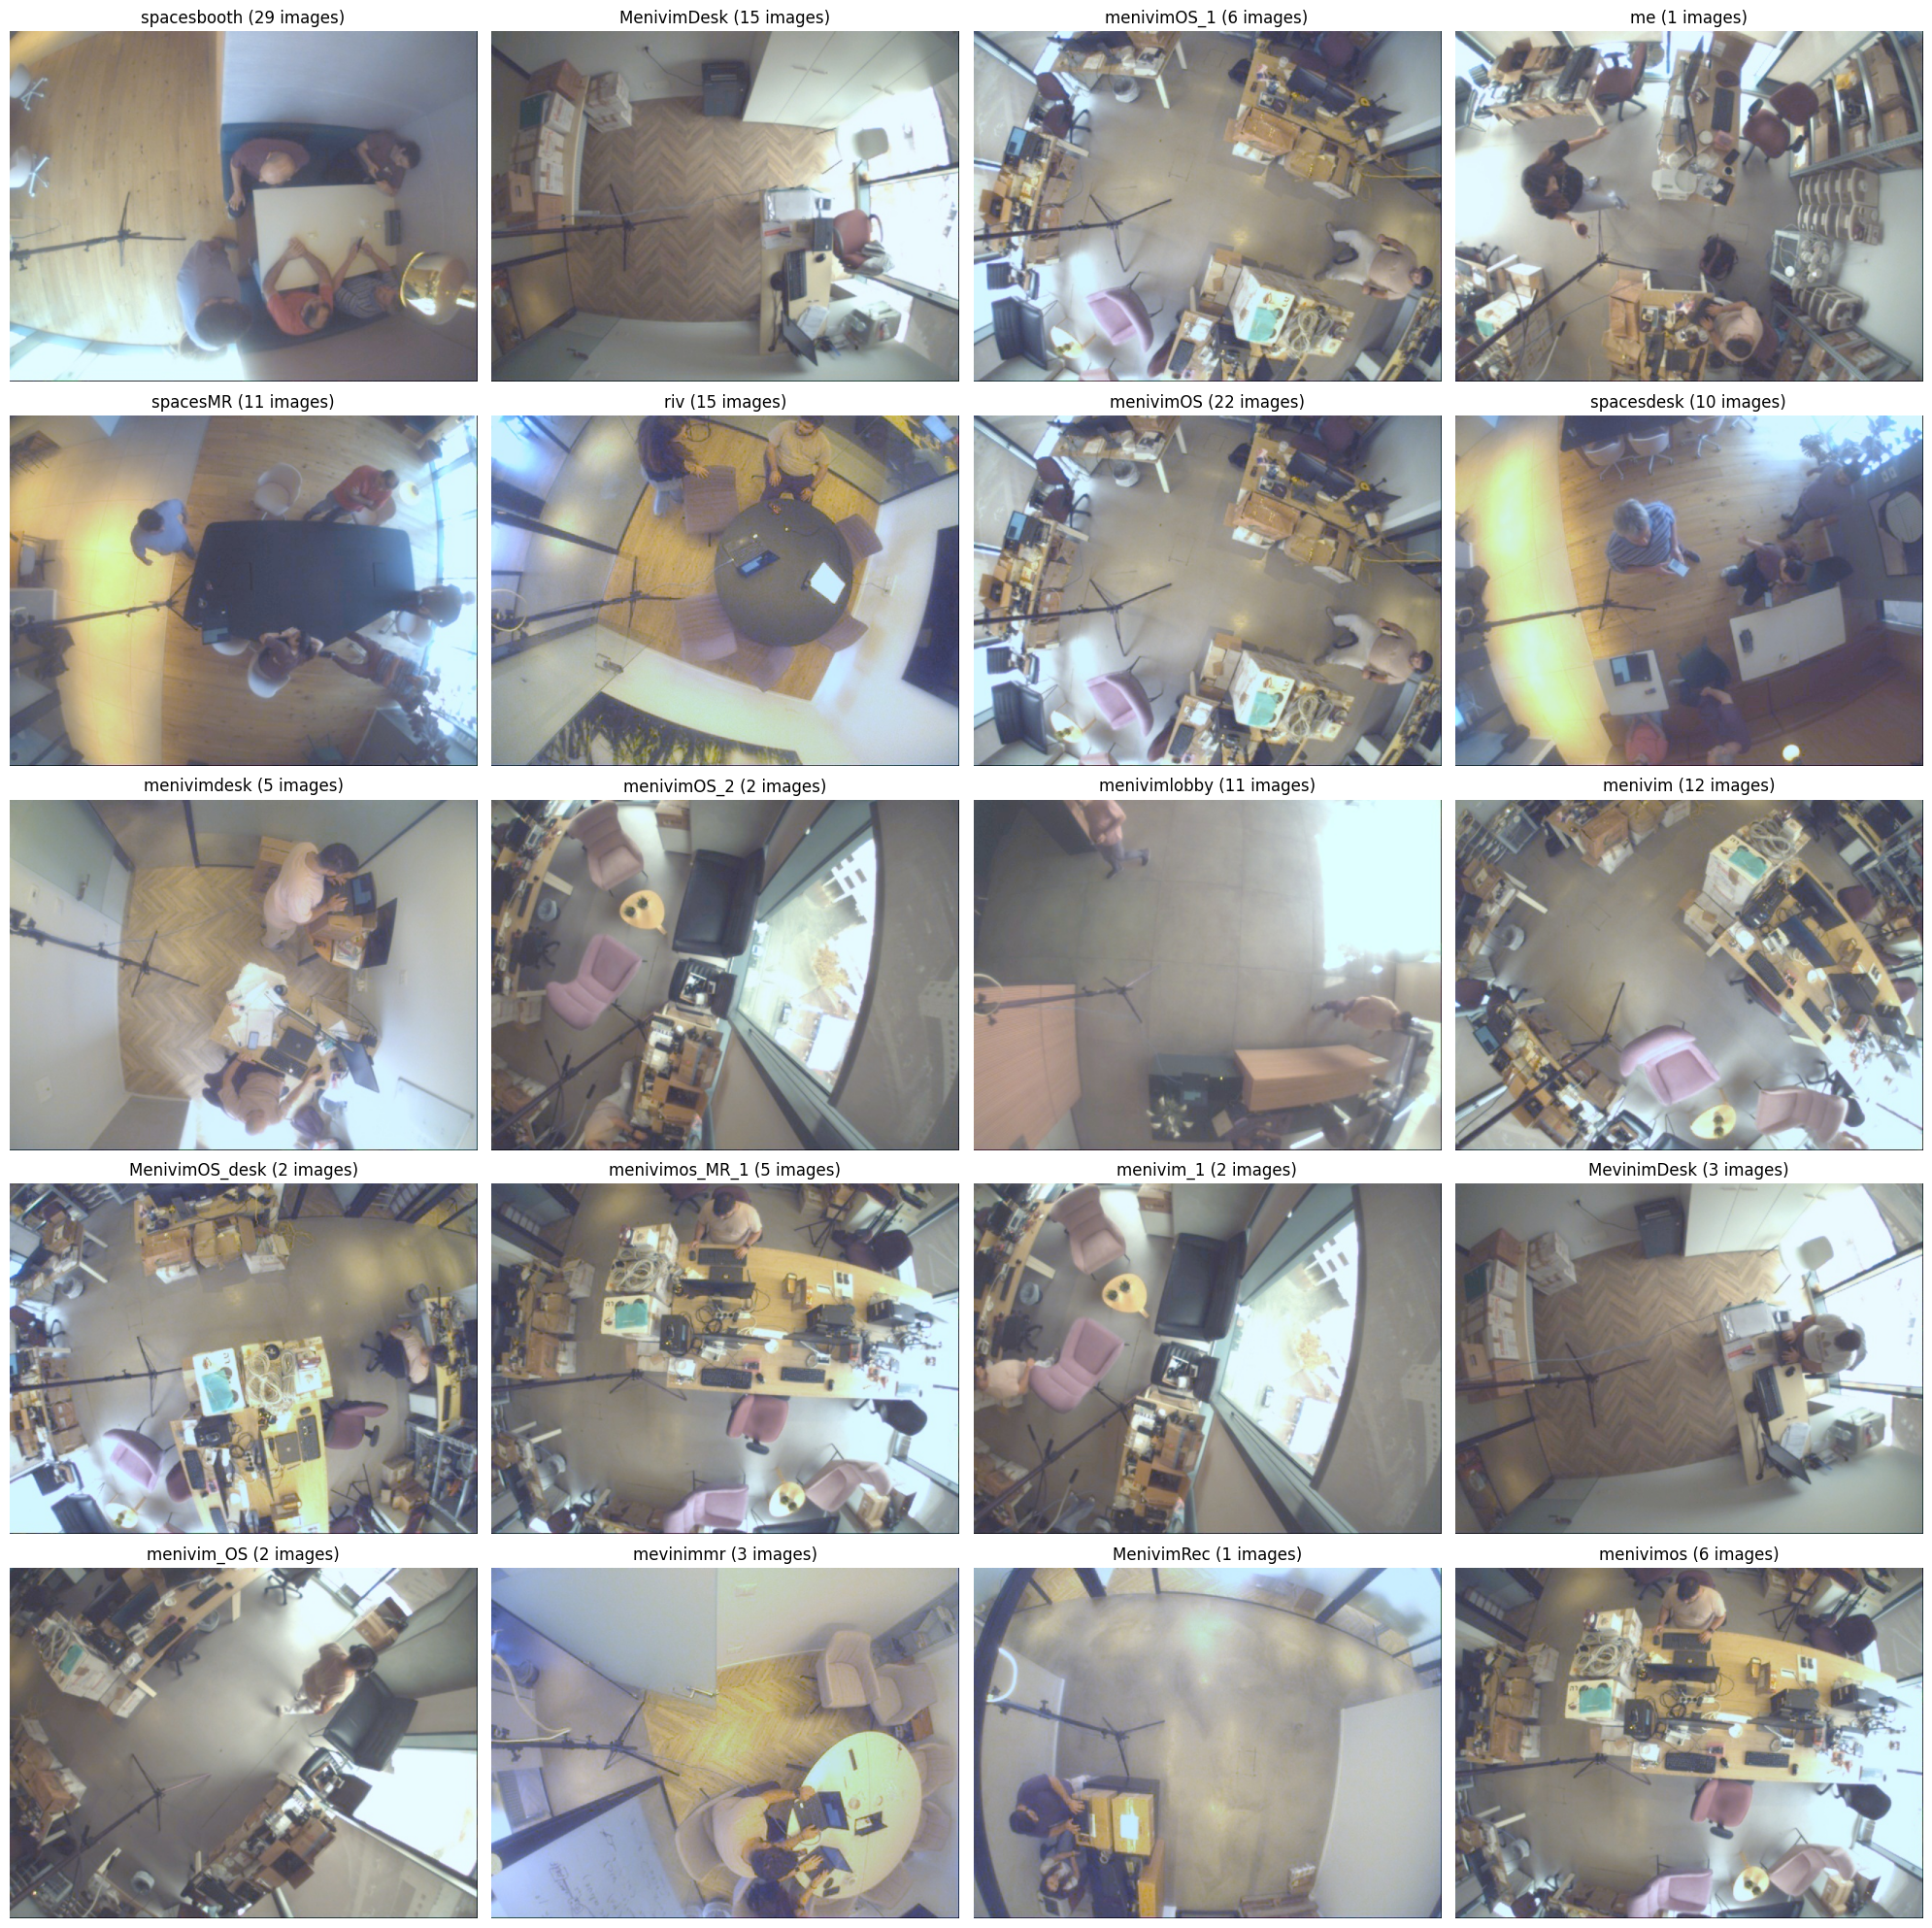

In [6]:
n = env_h_df["env"].unique()
print(f"Unique environments ({n.shape[0]}): {n}")


plt.figure(figsize=(20, 20))
for env_name in env_h_df["env"].unique():
    plt.subplot(5, 4, list(env_h_df["env"].unique()).index(env_name) + 1)
    subset = [i for i in img_names if f"_{env_name}_" in i]
    
    img_pth = os.path.join(HOLDOUT_SET_DIR, subset[0])
    img = Image.open(img_pth)
    plt.imshow(img)
    plt.title(f"{env_name} ({len(subset)} images)")
    plt.axis("off")
plt.tight_layout()
plt.show()
    

In [7]:
env_h_df["env"].unique().shape

(20,)

In [8]:
env_h_df.to_csv("holdout_set_env_height.csv", index=False)

{'spacesbooth': 29,
 'riv': 15,
 'MenivimDesk': 15,
 'menivimOS': 14,
 'menivimlobby': 11,
 'spacesMR': 11,
 'spacesdesk': 10,
 'menivim': 8,
 'menivimOS_1': 6,
 'menivimdesk': 5,
 'menivimos_MR_1': 5,
 'MevinimDesk': 3,
 'mevinimmr': 3,
 'menivimOS_2': 2,
 'MenivimOS_desk': 2,
 'menivim_1': 2,
 'menivim_OS': 2,
 'me': 1,
 'MenivimRec': 1,
 'menivimos': 1}

In [27]:
counts = env_h_df["env"].value_counts()

with open("holdout_cases_short_desctiption.json", "rt") as f:
    cases = json.load(f)

for env, count in counts.items():
    for case in cases:
        if case["name"] == env:
            case["num_images"] = int(count)
            break

with open("holdout_cases_short_desctiption_with_num_images.json", "wt") as f:
    json.dump(cases, f, indent=2)

Text(0.5, 1.0, 'Distribution of heights in test set')

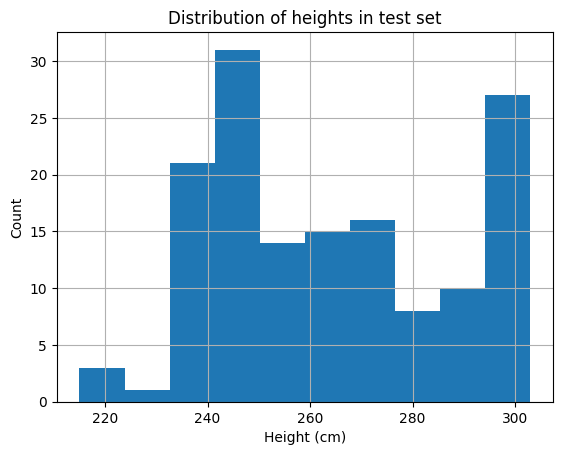

In [28]:
plt.hist(env_h_df["height"], bins=10)
plt.xlabel("Height (cm)")
plt.ylabel("Count")
plt.grid()
plt.title("Distribution of heights in test set")

In [29]:
# Add detections stats per case and save a new JSON
LABELS_HOLDOUT_DIR = "/home/klymy/data/cam4_revB/yolo_dataset/batch1_12_margin_15_bg_wb_alif/labels/holdout"
label_paths = glob.glob(os.path.join(LABELS_HOLDOUT_DIR, "*.txt"))

def count_detections(label_path: str) -> int:
    with open(label_path, "r") as f:
        return sum(1 for line in f if line.strip())

# Build per-image detections with env parsing
per_image = []
for lp in label_paths:
    base = os.path.basename(lp)
    parsed = extract_height_env(base)
    if parsed is None:
        continue
    _, env = parsed
    per_image.append({"env": env, "detections": count_detections(lp)})

detections_df = pd.DataFrame(per_image)
detections_stats = (
    detections_df.groupby("env")["detections"]
    .agg(["min", "max", "mean"])
    .reset_index()
)
detections_stats["mean"] = detections_stats["mean"].round(2)

with open("holdout_cases_short_desctiption_with_num_images.json", "rt") as f:
    cases = json.load(f)

stats_by_env = {
    row["env"]: {
        "min": int(row["min"]),
        "max": int(row["max"]),
        "average": float(row["mean"]),
    }
    for _, row in detections_stats.iterrows()
}

for case in cases:
    case_name = case.get("name")
    if case_name in stats_by_env:
        case["detections"] = stats_by_env[case_name]

output_path = "holdout_cases_short_desctiption_with_num_images_and_detections.json"
with open(output_path, "wt") as f:
    json.dump(cases, f, indent=2)

output_path


'holdout_cases_short_desctiption_with_num_images_and_detections.json'

In [30]:
# Show detections summary table
with open("holdout_cases_short_desctiption_with_num_images_and_detections.json", "rt") as f:
    cases_with_det = json.load(f)

df_cases = pd.json_normalize(cases_with_det)
df_cases


,name,location_type,frame_position,background_complexity,heights,num_images,detections.min,detections.max,detections.average
0,spacesbooth,Meeting Room (4 seats),Center of DA,Medium,"[234, 272]",29,4,6,4.90
1,MenivimDesk,Office Room (1 2 desks),On edge of DA,Strong,"[257, 260]",15,0,7,1.20
2,menivimOS_1,"Open Space (big area, 3 desks)",Center of DA,Strong,[250],6,1,1,1.00
3,me,"Open Space (big area, 3 desks)",Center of DA,Strong,[250],1,2,2,2.00
4,spacesMR,Meeting Room (4 seats),Center of DA,Medium,"[234, 257]",11,5,5,5.00
5,riv,Small Meeting Room (4 seats),Center of DA,Simple,"[243, 277, 278, 279, 281]",15,2,6,3.73
6,menivimOS,"Open Space (big area, 3 desks)",Center of DA,Strong,"[229, 230, 250, 277, 291, 295, 328]",14,0,1,0.93
7,spacesdesk,"Open Space (big area, 3 desks)",Near edge of DA,Strong,"[243, 277]",10,5,5,5.00
8,menivimdesk,Office Room (1 2 desks),Center of DA,Medium,[250],5,2,2,2.00
9,menivimOS_2,"Open Space (big area, 3 desks)",On edge of DA,Strong,[250],2,1,2,1.50


In [31]:
df_cases.to_csv("holdout_cases_summary.csv", index=False)